# English movie-review sentiment classification with a bidirectional LSTM

**Learning outcomes:** build a vocabulary from training data, encode and pad reviews,
train an order-sensitive model, select a validation checkpoint, and predict English labels.

This lesson uses IMDb movie reviews instead of Chinese hotel reviews. It uses an
English tokenizer rather than Chinese word segmentation. Both framework editions
share the same prepared data and label mapping, but have separate environments and outputs.

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('paddlepaddle').split("+")[0] == '3.3.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('paddlepaddle' + ":", version('paddlepaddle'))
print("Run mode:", 'Default classroom training parameters')

Python: 3.12.12
paddlepaddle: 3.3.1
Run mode: Default classroom training parameters


**Expected output:**

```text
Python: 3.12.12
paddlepaddle: 3.3.1
Run mode: Default classroom training parameters
```

In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None and (start / "english" / "COURSE_ROOT").is_file():
    COURSE = start / "english"
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'/Users/will/workspace/deep-learning-lab/english/data/torch-cache'

**Expected output:**

```text
'…/deep-learning-lab/english/data/torch-cache'
```

(Inside the quoted output `…` stands for the repository's absolute path prefix on the machine that ran the notebook; yours will show your own path.)

In [3]:
FRAMEWORK = "paddle"
EXPERIMENT = "lstm-sentiment"

import json
import random
import numpy as np
from course_data import load_reviews, tokenize, build_vocab, encode, LABELS

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
DATA = COURSE / "03-sentiment-analysis" / "data"
OUTPUT = COURSE / "03-sentiment-analysis" / "outputs" / FRAMEWORK / EXPERIMENT
OUTPUT.mkdir(parents=True, exist_ok=True)
train_rows = load_reviews(DATA, "train", 64 if SMOKE else 4000)
validation_rows = load_reviews(DATA, "validation", 32 if SMOKE else 1000)
test_rows = load_reviews(DATA, "test", 32 if SMOKE else 1000)
print("Split sizes:", len(train_rows), len(validation_rows), len(test_rows))
print("Labels:", LABELS)

Split sizes: 4000 1000 1000
Labels: ['negative', 'positive']


**Expected output:**

```text
Split sizes: 4000 1000 1000
Labels: ['negative', 'positive']
```

## 1. Build a vocabulary without test leakage

`<pad>` is ID 0; `<unk>` is ID 1. Truncate very long reviews for the classroom
experiment and track true lengths. The vocabulary is fitted on training text only.
Do not remove "not" or other negation words as stopwords.

In [4]:
MAX_LENGTH = 40 if SMOKE else 200
vocab = build_vocab([row["text"] for row in train_rows], max_words=20000)
(OUTPUT / "vocab.json").write_text(json.dumps(vocab, indent=2), encoding="utf-8")
ids, length = encode("The acting wasn't convincing, but I liked the music.", vocab, MAX_LENGTH)
print("Vocabulary size:", len(vocab), "True length:", length)
print("First token IDs:", ids[:12])
print("English label mapping:", dict(enumerate(LABELS)))

Vocabulary size: 20000 True length: 9
First token IDs: [2, 116, 264, 1070, 18, 10, 434, 2, 202, 0, 0, 0]
English label mapping: {0: 'negative', 1: 'positive'}


**Expected output:**

```text
Vocabulary size: 20000 True length: 9
First token IDs: [2, 116, 264, 1070, 18, 10, 434, 2, 202, 0, 0, 0]
English label mapping: {0: 'negative', 1: 'positive'}
```

## 2. Define the model and training step

Embedding maps IDs to vectors. A bidirectional LSTM summarizes the review in both
directions. Concatenated final states feed a two-class linear layer. Sequence lengths
are passed to the recurrent computation so padding does not contaminate final states.
Gradient clipping limits unusually large updates.

In [5]:
import paddle
from paddle import nn

paddle.seed(SEED)
paddle.set_device("gpu" if paddle.is_compiled_with_cuda() else "cpu")

class ReviewDataset(paddle.io.Dataset):
    def __init__(self, rows):
        super().__init__()
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        ids, length = encode(row["text"], vocab, MAX_LENGTH)
        return np.asarray(ids, dtype="int64"), np.int64(length), np.int64(row["label"])

def make_loader(rows, shuffle=False):
    return paddle.io.DataLoader(ReviewDataset(rows), batch_size=32, shuffle=shuffle,
                                num_workers=0, return_list=True)

class SentimentLSTM(nn.Layer):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 64, padding_idx=0)
        self.lstm = nn.LSTM(64, 64, direction="bidirectional")
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(128, 2)

    def forward(self, ids, lengths):
        embedded = self.embedding(ids)
        # sequence_length prevents padding from becoming part of the final state.
        _, (hidden, _) = self.lstm(embedded, sequence_length=lengths)
        return self.classifier(self.dropout(paddle.concat([hidden[-2], hidden[-1]], axis=1)))

model = SentimentLSTM(len(vocab))
train_loader = make_loader(train_rows, True)
validation_loader = make_loader(validation_rows)
test_loader = make_loader(test_rows)
criterion = nn.CrossEntropyLoss()
optimizer = paddle.optimizer.Adam(learning_rate=0.001, parameters=model.parameters(),
                                  grad_clip=nn.ClipGradByGlobalNorm(1.0))

def run_epoch(loader, training=False):
    model.train() if training else model.eval()
    loss_total, correct, count = 0.0, 0, 0
    with paddle.set_grad_enabled(training):
        for ids, lengths, labels in loader:
            if training:
                optimizer.clear_grad()
            logits = model(ids, lengths)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            size = int(labels.shape[0])
            loss_total += float(loss.item()) * size
            correct += int((logits.argmax(axis=1) == labels).astype("int64").sum().item())
            count += size
    return loss_total / count, correct / count

def save_weights(path):
    paddle.save(model.state_dict(), str(path))

def load_weights(path):
    model.set_state_dict(paddle.load(str(path)))

def predict(texts):
    encoded = [encode(text, vocab, MAX_LENGTH) for text in texts]
    ids = paddle.to_tensor([item[0] for item in encoded], dtype="int64")
    lengths = paddle.to_tensor([item[1] for item in encoded], dtype="int64")
    model.eval()
    with paddle.no_grad():
        return paddle.nn.functional.softmax(model(ids, lengths), axis=1).numpy()

/Users/will/env_dl_uv/.venv/lib/python3.12/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
PLEASE USE OMP_NUM_THREADS WISELY.


**Expected output:**

```text
/Users/will/env_dl_uv/.venv/lib/python3.12/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
WARNING: OMP_NUM_THREADS set to 2, not 1. The computation speed will not be optimized if you use data parallel. It will fail if this PaddlePaddle binary is compiled with OpenBlas since OpenBlas does not support multi-threads.
PLEASE USE OMP_NUM_THREADS WISELY.
```

## 3. Train and select by validation accuracy

In [6]:
EPOCHS = 1 if SMOKE else 5
checkpoint = OUTPUT / ("best_model.pt" if FRAMEWORK == "pytorch" else "best_model.pdparams")
history, best_accuracy = [], -1.0
for epoch in range(EPOCHS):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(validation_loader)
    history.append([train_loss, val_loss, train_accuracy, val_accuracy])
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        save_weights(checkpoint)
    print(f"Epoch {epoch + 1}/{EPOCHS} | training loss {train_loss:.4f} | "
          f"validation loss {val_loss:.4f} | validation accuracy {val_accuracy:.3f}")

Epoch 1/5 | training loss 0.6829 | validation loss 0.5194 | validation accuracy 0.740


Epoch 2/5 | training loss 0.3503 | validation loss 0.4340 | validation accuracy 0.820


Epoch 3/5 | training loss 0.1109 | validation loss 0.6338 | validation accuracy 0.798


Epoch 4/5 | training loss 0.0535 | validation loss 0.5728 | validation accuracy 0.796


Epoch 5/5 | training loss 0.0106 | validation loss 0.8443 | validation accuracy 0.825


**Expected output:**

```text
Epoch 1/5 | training loss 0.6829 | validation loss 0.5194 | validation accuracy 0.740
Epoch 2/5 | training loss 0.3503 | validation loss 0.4340 | validation accuracy 0.820
Epoch 3/5 | training loss 0.1109 | validation loss 0.6338 | validation accuracy 0.798
Epoch 4/5 | training loss 0.0535 | validation loss 0.5728 | validation accuracy 0.796
Epoch 5/5 | training loss 0.0106 | validation loss 0.8443 | validation accuracy 0.825
```

## 4. Reload and evaluate on held-out test reviews

Test accuracy: 0.808; test loss: 0.8735


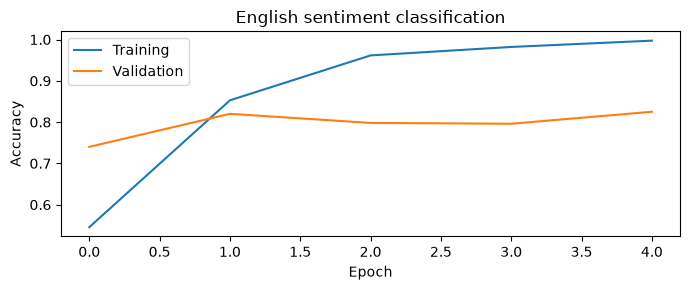

In [7]:
load_weights(checkpoint)
test_loss, test_accuracy = run_epoch(test_loader)
print(f"Test accuracy: {test_accuracy:.3f}; test loss: {test_loss:.4f}")
metrics = {"test_accuracy": test_accuracy, "test_loss": test_loss,
           "best_validation_accuracy": best_accuracy, "seed": SEED,
           "smoke_test": SMOKE, "max_length": MAX_LENGTH, "labels": LABELS,
           "split_sizes": [len(train_rows), len(validation_rows), len(test_rows)]}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
import matplotlib.pyplot as plt
values = np.asarray(history)
fig, axis = plt.subplots(figsize=(7, 3))
axis.plot(values[:, 2], label="Training")
axis.plot(values[:, 3], label="Validation")
axis.set(title="English sentiment classification", xlabel="Epoch", ylabel="Accuracy")
axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "accuracy.png")
plt.show()

**Expected output:**

```text
Test accuracy: 0.808; test loss: 0.8735
```

**Expected output (image):**

![Reload and evaluate on held-out test reviews](../assets/03-lstm-sentiment-1.png)

*Reload and evaluate on held-out test reviews*

## 5. Predict new English reviews

In [8]:
reviews = ["The movie was wonderful and the acting was excellent.",
           "The plot was boring and the ending was disappointing.",
           "I expected to hate it, but it was not bad at all."]
probabilities = predict(reviews)
for text, scores in zip(reviews, probabilities):
    label = int(np.argmax(scores))
    print(f"{LABELS[label]} ({scores[label]:.3f}): {text}")

assert probabilities.shape == (len(reviews), 2)
assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
# The same review should not change prediction because of other batch members.
assert np.allclose(predict([reviews[0]])[0], probabilities[0], atol=1e-5)
print("Predictions can be wrong, especially after a short classroom run.")

positive (0.998): The movie was wonderful and the acting was excellent.
negative (1.000): The plot was boring and the ending was disappointing.
negative (0.996): I expected to hate it, but it was not bad at all.
Predictions can be wrong, especially after a short classroom run.


**Expected output:**

```text
positive (0.998): The movie was wonderful and the acting was excellent.
negative (1.000): The plot was boring and the ending was disappointing.
negative (0.996): I expected to hate it, but it was not bad at all.
Predictions can be wrong, especially after a short classroom run.
```

## Exercises

Compare a unidirectional and bidirectional model. Change the maximum length and
measure truncation frequency. Inspect negation and mixed reviews. Keep all tuning
on the validation set. To reproduce predictions later, restore the vocabulary,
maximum length, architecture, class mapping, and weights together.

For an already fine-tuned English transformer, use the optional pretrained-model
lesson in the PyTorch route. Its SST-2 training task differs from this IMDb experiment;
its published scores are not this course's results.